In [14]:
# %%
import os

import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
from cluster_weather_years.constants import BASE_OUTPUT
from cluster_weather_years.functions import build_df_random
from cluster_weather_years.evaluation import qq_plot, ecdf_comparison

In [15]:
NUM_DRAWS = int(1e5)  # number of random draws to compare with
NUM_CLUSTERS = 30  # number of Climate Years to select
ALL_MATCH_COUNTRIES = ["NL"]
RUN_ID = "NL_20251024_1320"  # NL 30y; Run to analyze and compare to random draws
# RUN_ID = "NL_20251104_1108"  # NL 30y seasonal_wasserstein.
# RUN_ID = "NL_20251023_0942"  # NL 5y; Run to analyze and compare to random draws
seed = 42

# 1. Preliminaries

In [16]:
filename = (
    f"{ALL_MATCH_COUNTRIES}_{NUM_DRAWS}_draws_{NUM_CLUSTERS}_clusters_run_{RUN_ID}"
)

df_wass_scores = pd.read_csv(
    f"{BASE_OUTPUT}/metrics_random_draws/wasserstein_{ALL_MATCH_COUNTRIES}_{NUM_DRAWS}_draws_{NUM_CLUSTERS}_clusters_run_{RUN_ID}.csv",
    index_col=0,
)

df_score_all_good = pd.read_csv(
    f"{BASE_OUTPUT}/metrics_random_draws/univariate_scores_{ALL_MATCH_COUNTRIES}_{NUM_DRAWS}_draws_{NUM_CLUSTERS}_clusters_run_{RUN_ID}.csv",
    index_col=0,
)

with open(
    f"{BASE_OUTPUT}/metrics_random_draws/final_datasets_{filename}.pkl", "rb"
) as f:
    final_datasets = pickle.load(f)

SA_OUTPUT_DIR = os.path.join(BASE_OUTPUT, "simulated_annealing")

df_selections = pd.read_csv(
    os.path.join(SA_OUTPUT_DIR, f"run_{RUN_ID}/results_grid.csv"), index_col=0
)
NUM_SA = len(df_selections)

# build df
DF_PROD_DEMAND_FNAME = os.path.join(
    BASE_OUTPUT, "dataframes/df_prod_demand_daily_multi_country_WRONG_CAPACITIES.csv"
)

df_daily = pd.read_csv(DF_PROD_DEMAND_FNAME, index_col=0)
df_daily["Date"] = pd.to_datetime(df_daily["Date"])
df_daily = df_daily.query("Hydrological_year > 2014 and Hydrological_year < 2044")

In [17]:
# settings for random-draws
df_idx = df_daily.set_index(["model", "Hydrological_year"]).sort_index()
keys = df_idx.index.unique().to_numpy()
rng = np.random.default_rng(seed)

In [18]:
# find worst variable per dataset, based on QQ-MAE
idx_qqmae = df_score_all_good.groupby("ds_name")["qq_mae"].idxmax()
df_worst_qqmae = df_score_all_good.loc[idx_qqmae].reset_index(drop=True)

idx_qqmae_high = df_score_all_good.groupby("ds_name")["qq_mae_high"].idxmax()
df_worst_qqmae_high = df_score_all_good.loc[idx_qqmae_high].reset_index(drop=True)

df_worst_qqmae = df_worst_qqmae.sort_values("qq_mae").rename(
    columns={"variable": "bottleneck_variable"}
)
df_worst_qqmae = df_worst_qqmae.merge(df_wass_scores, on="ds_name").sort_values(
    "Wasserstein"
)
df_worst_qqmae["ds_type"] = df_worst_qqmae["ds_name"].apply(
    lambda x: "Optimized" if not x.startswith("Random") else "Random"
)
# rename K_medoids type, for separate plotting
df_worst_qqmae.loc[df_worst_qqmae["ds_name"] == "K_medoids", "ds_type"] = "K_medoids"

# rank datasets based on all metrics
df_ranked = df_worst_qqmae.copy()
for metric in df_worst_qqmae.columns[2:-1]:
    df_ranked[metric] = df_ranked[metric].rank()

df_ranked["total_rank"] = df_ranked[df_ranked.columns[2:-1]].mean(axis=1)

df_ranked["relevant_rank"] = df_ranked[df_ranked.columns[4:-2]].mean(axis=1)
df_ranked = df_ranked.sort_values("relevant_rank")

In [19]:
df_worst = df_worst_qqmae.merge(
    df_worst_qqmae_high[["ds_name", "qq_mae_high"]], on="ds_name"
)
df_worst = df_worst.rename(
    columns={"qq_mae_high_x": "old_qq_mae_high", "qq_mae_high_y": "qq_mae_high"}
)

# 2. Find best dataset

In [20]:
# shows dataset that is 'least bad' on top
df_worst_qqmae.sort_values("qq_mae")

,ds_name,bottleneck_variable,d_mean,energy_distance_score,qq_mae,qq_mae_low,qq_mae_high,Wasserstein,ds_type
0,Multi-country 25,NL_SOLAR_prod,0.001956,0.043465,0.455597,0.445615,0.454288,0.646917,Optimized
1,Random_N 55239,NL_OFF_prod,0.000690,0.040725,0.474644,0.184403,0.408218,0.795518,Random
2,Multi-country 23,NL_OFF_prod,0.000399,0.042892,0.478327,0.353096,0.166870,0.651209,Optimized
3,Multi-country 5,NL_SOLAR_prod,0.000149,0.045655,0.481716,0.366180,0.614072,0.678526,Optimized
4,Multi-country 17,NL_SOLAR_prod,0.000932,0.045363,0.482212,0.083224,0.982907,0.681311,Optimized
...,...,...,...,...,...,...,...,...,...
590,Random_N 98055,NL_OFF_prod,0.000036,0.074761,0.939141,0.560735,1.220842,0.924639,Random
591,Random_N 8355,NL_SOLAR_prod,0.005699,0.074043,0.942507,0.074175,2.385048,1.039207,Random
592,Random_N 32227,NL_OFF_prod,0.002040,0.070501,0.943501,0.540155,1.251405,0.882441,Random
593,Random_N 1364,NL_SOLAR_prod,0.003027,0.072199,0.949531,0.926327,3.311102,1.037635,Random


In [21]:
df_worst_qqmae.query('ds_type == "Optimized"').sort_values("qq_mae")

,ds_name,bottleneck_variable,d_mean,energy_distance_score,qq_mae,qq_mae_low,qq_mae_high,Wasserstein,ds_type
0,Multi-country 25,NL_SOLAR_prod,0.001956,0.043465,0.455597,0.445615,0.454288,0.646917,Optimized
2,Multi-country 23,NL_OFF_prod,0.000399,0.042892,0.478327,0.353096,0.166870,0.651209,Optimized
3,Multi-country 5,NL_SOLAR_prod,0.000149,0.045655,0.481716,0.366180,0.614072,0.678526,Optimized
4,Multi-country 17,NL_SOLAR_prod,0.000932,0.045363,0.482212,0.083224,0.982907,0.681311,Optimized
7,Multi-country 26,NL_OFF_prod,0.000393,0.042617,0.524832,0.452422,0.239591,0.657144,Optimized
8,Multi-country 4,NL_OFF_prod,0.001002,0.047321,0.535630,0.242849,0.361089,0.654007,Optimized
9,Multi-country 6,NL_Demand,0.000191,0.074580,0.537534,0.000000,1.202120,0.621122,Optimized
14,Multi-country 19,NL_SOLAR_prod,0.001650,0.062122,0.554366,0.162805,0.489500,0.647169,Optimized
16,Multi-country 21,NL_OFF_prod,0.000213,0.046806,0.556243,0.293746,0.648666,0.651290,Optimized
17,Multi-country 2,NL_OFF_prod,0.000610,0.046013,0.560789,0.506280,0.477760,0.624701,Optimized


In [22]:
# shows dataset that is 'best' on top
df_wass_scores.sort_values("Wasserstein")

,ds_name,Wasserstein
0,Multi-country 1,0.594144
17,Multi-country 18,0.602236
9,Multi-country 10,0.605094
11,Multi-country 12,0.619239
5,Multi-country 6,0.621122
...,...,...
224,Random_N 28624,1.271463
546,Random_N 91830,1.281549
152,Random_N 17041,1.284399
533,Random_N 89297,1.320539


In [23]:
df_ranked

,ds_name,bottleneck_variable,d_mean,energy_distance_score,qq_mae,qq_mae_low,qq_mae_high,Wasserstein,ds_type,total_rank,relevant_rank
45,Multi-country 10,NL_OFF_prod,84.0,29.0,46.0,167.0,7.0,3.0,Optimized,56.000000,55.75
68,Random_N 31793,NL_SOLAR_prod,497.0,168.0,69.0,44.0,51.0,133.0,Random,160.333333,74.25
5,Random_N 15205,NL_SOLAR_prod,443.0,21.0,6.0,30.0,213.0,50.0,Random,127.166667,74.75
72,Random_N 83509,NL_OFF_prod,38.0,100.0,73.0,64.0,102.0,61.0,Random,73.000000,75.00
14,Multi-country 19,NL_SOLAR_prod,280.0,155.0,15.0,86.0,200.0,11.0,Optimized,124.500000,78.00
...,...,...,...,...,...,...,...,...,...,...,...
452,Random_N 45105,NL_SOLAR_prod,310.0,243.0,453.0,555.0,549.0,526.0,Random,439.333333,520.75
588,Random_N 92676,NL_SOLAR_prod,374.0,535.0,589.0,525.0,567.0,430.0,Random,503.333333,527.75
536,Random_N 61937,NL_SOLAR_prod,546.0,545.0,537.0,579.0,508.0,529.0,Random,540.666667,538.25
589,Random_N 16212,NL_SOLAR_prod,420.0,561.0,590.0,464.0,591.0,572.0,Random,533.000000,554.25


In [24]:
def calc_pareto_mask(df, cols):
    X = df.loc[:, cols].to_numpy()
    n = len(df)
    m = np.ones(n, dtype=bool)
    for i in range(n):
        if not m[i]:
            continue
        # point j dominates i if j <= i in all and < in at least one (lower=better)
        dom_i = np.all(X <= X[i], axis=1) & np.any(X < X[i], axis=1)
        if dom_i.any():
            m[i] = False
    return m

In [25]:
metric_1 = "qq_mae"
metric_2 = "Wasserstein"
metric_3 = "qq_mae_high"  # optional

pareto_mask_3d = calc_pareto_mask(df_worst, cols=(metric_1, metric_2, metric_3))
pareto_mask_2d = calc_pareto_mask(df_worst, cols=(metric_1, metric_2))
pareto_front_3d = df_worst.loc[pareto_mask_3d]
pareto_front_2d = df_worst.loc[pareto_mask_2d]

Text(0.5, 1.0, "Region = ['NL'], Num_years = 30 \n Num_SA = 45, Num_random = 100000")

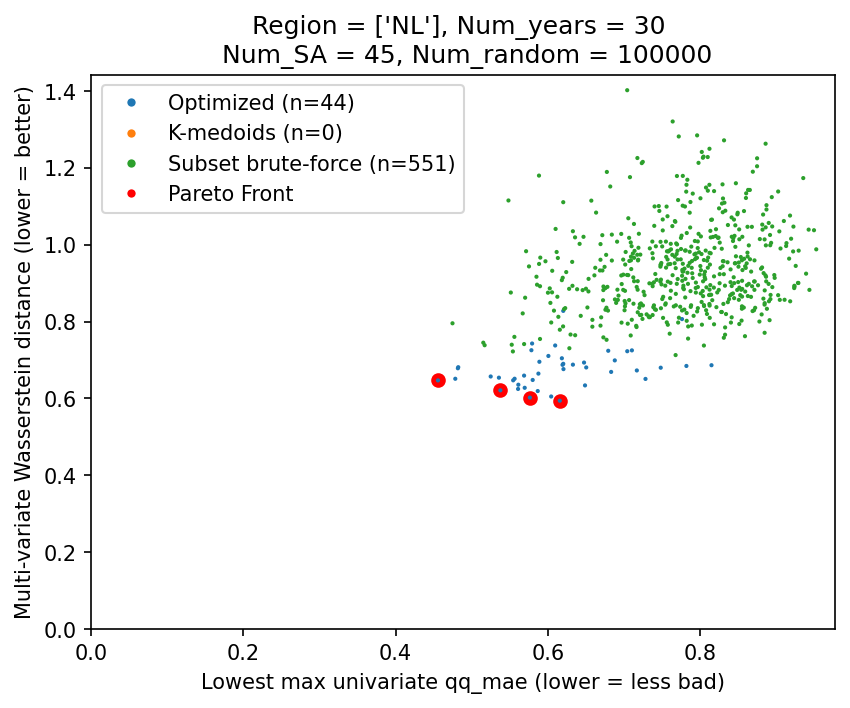

In [26]:
colors = (
    df_worst_qqmae["ds_type"]
    .map({"Optimized": "C0", "K_medoids": "C1", "Random": "C2"})
    .fillna("k")
    .to_list()
)

n_opt = int((df_worst_qqmae["ds_type"] == "Optimized").sum())
n_kmed = int((df_worst_qqmae["ds_type"] == "K_medoids").sum())
n_rand = int((df_worst_qqmae["ds_type"] == "Random").sum())


plt.figure(dpi=150)

plt.scatter(
    pareto_front_2d[metric_1], pareto_front_2d[metric_2], c="r", label="Pareto front"
)


plt.scatter(
    df_worst_qqmae[metric_1],
    df_worst_qqmae[metric_2],
    c=colors,
    s=1,
)


plt.xlabel("Lowest max univariate qq_mae (lower = less bad)")
plt.ylabel("Multi-variate Wasserstein distance (lower = better)")
plt.legend(
    handles=[
        plt.Line2D(
            [0],
            [0],
            marker="o",
            color="w",
            label=f"Optimized (n={n_opt})",
            markerfacecolor="C0",
            markersize=5,
        ),
        plt.Line2D(
            [0],
            [0],
            marker="o",
            color="w",
            label=f"K-medoids (n={n_kmed})",
            markerfacecolor="C1",
            markersize=5,
        ),
        plt.Line2D(
            [0],
            [0],
            marker="o",
            color="w",
            label=f"Subset brute-force (n={n_rand})",
            markerfacecolor="C2",
            markersize=5,
        ),
        plt.Line2D(
            [0],
            [0],
            marker="o",
            color="w",
            label=f"Pareto Front",
            markerfacecolor="r",
            markersize=5,
        ),
    ]
)
plt.xlim(left=0)
plt.ylim(bottom=0)
plt.title(
    f"Region = {ALL_MATCH_COUNTRIES}, Num_years = {NUM_CLUSTERS} \n Num_SA = {NUM_SA}, Num_random = {NUM_DRAWS}"
)

Text(0.5, 0, 'qq_mae_high')

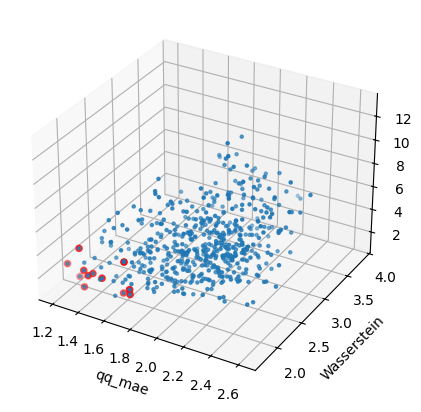

In [14]:
fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(projection="3d")
ax.scatter(
    pareto_front_3d[metric_1],
    pareto_front_3d[metric_2],
    pareto_front_3d[metric_3],
    s=20,
    c="r",
)
ax.scatter(df_worst[metric_1], df_worst[metric_2], df_worst[metric_3], s=5)

ax.set_xlabel(metric_1)
ax.set_ylabel(metric_2)
ax.set_zlabel(metric_3, labelpad=12)  # push z-label outwards

# 3. Plot best dataset

In [15]:
pareto_front_2d.sort_values("Wasserstein")

,ds_name,bottleneck_variable,d_mean,energy_distance_score,qq_mae,qq_mae_low,old_qq_mae_high,Wasserstein,ds_type,qq_mae_high
0,Multi-country 2,NL_OFF_prod,0.001787,0.142462,1.698640,0.701697,2.135004,1.716734,Optimized,4.939866
1,Multi-country 7,NL_SOLAR_prod,0.005763,0.133303,1.523889,0.784383,2.549164,1.722733,Optimized,2.918006
3,Multi-country 15,NL_OFF_prod,0.001194,0.114917,1.410102,0.991713,2.673496,1.737611,Optimized,2.673496
8,Multi-country 5,NL_SOLAR_prod,0.001772,0.120970,1.330263,0.312485,2.066361,1.773115,Optimized,4.609038
19,Multi-country 25,NL_OFF_prod,0.003492,0.100599,1.196625,1.056926,1.333630,1.856638,Optimized,2.496428


## 3.1 Best vs least-bad and vs best-random draw

In [16]:
# df_best_sa = final_datasets["Multi-country 2"]
df_best_sa = final_datasets["Multi-country 1"]

df_least_bad_sa = final_datasets["Multi-country 25"]
df_best_random = final_datasets["Random_N 15205"]
df_random = build_df_random(df_idx, keys, rng, num_random=NUM_CLUSTERS)
cols = ["NL_OFF_prod", "NL_ON_prod", "NL_SOLAR_prod", "NL_Demand"]

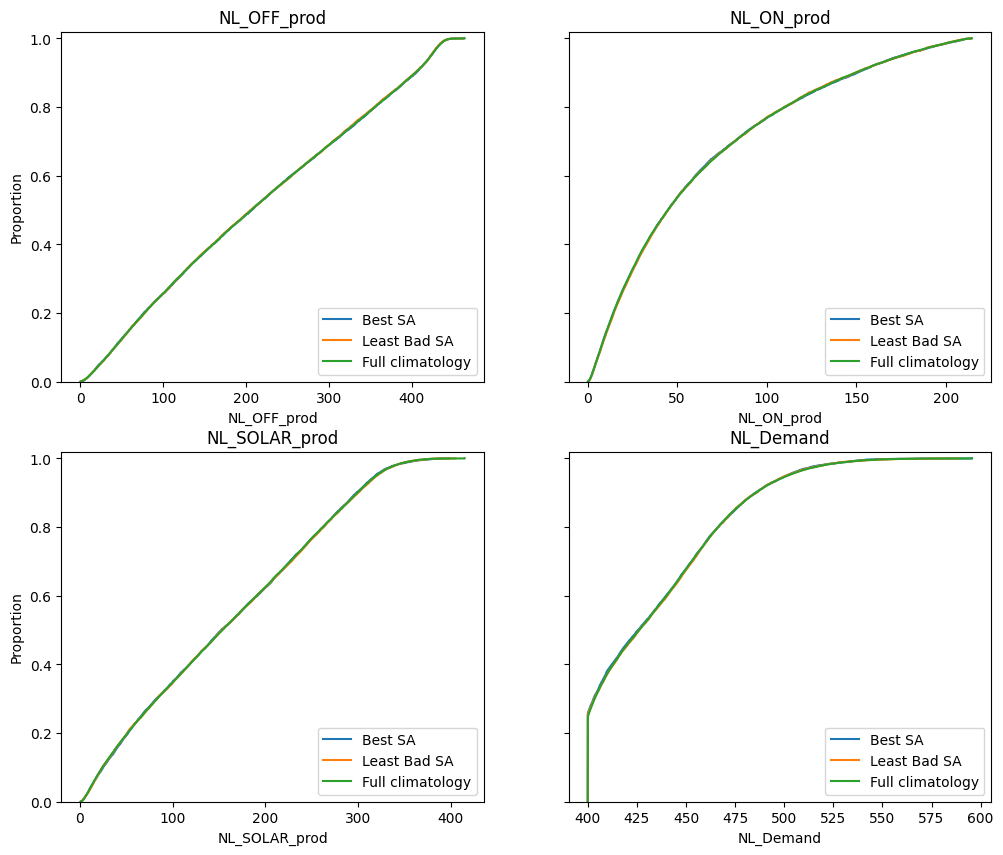

In [22]:
ecdf_comparison(
    df_daily, {"Best SA": df_best_sa, "Least Bad SA": df_least_bad_sa}, columns=cols
)

(<Figure size 1200x1000 with 4 Axes>, <Figure size 1200x1000 with 4 Axes>)

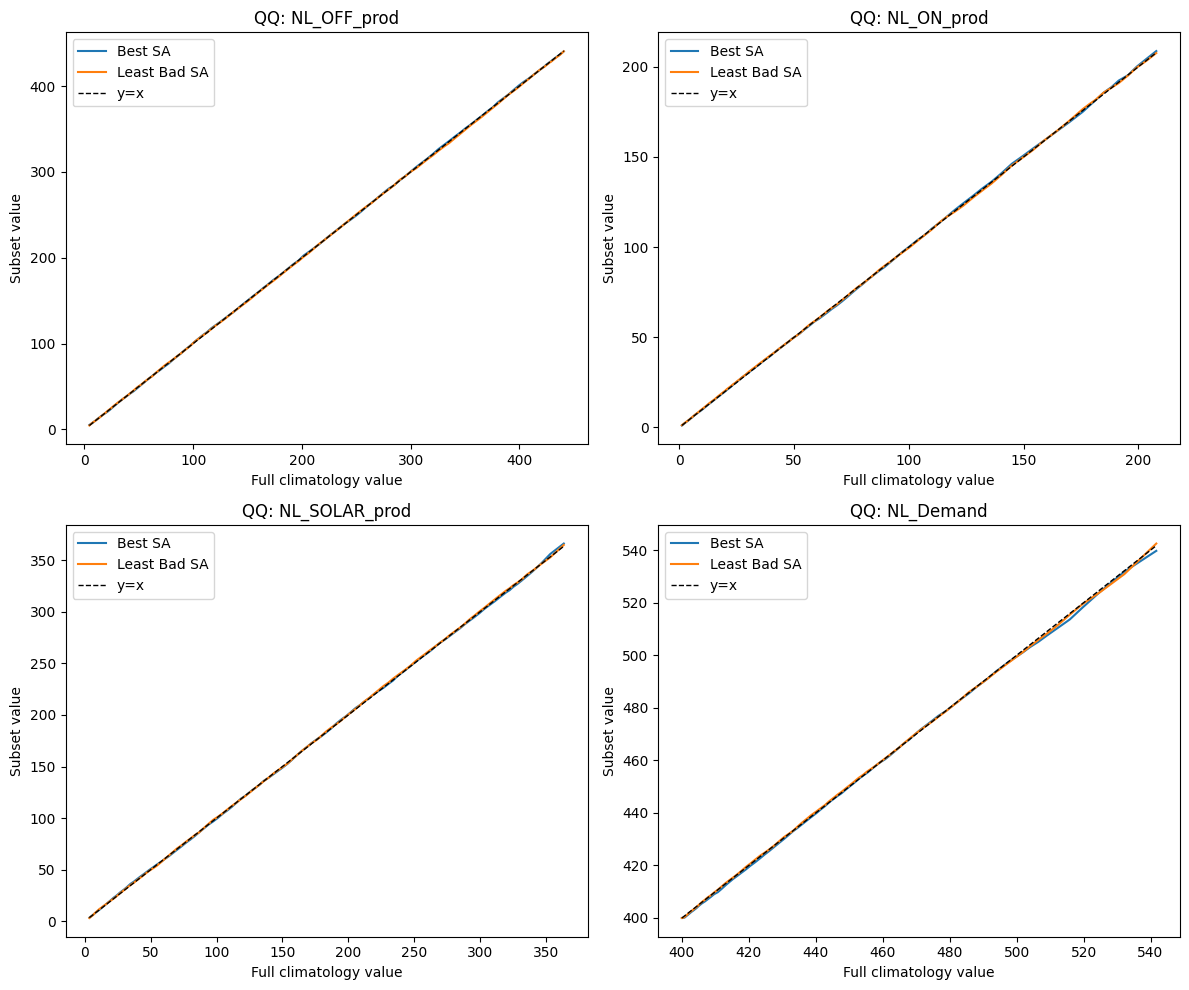

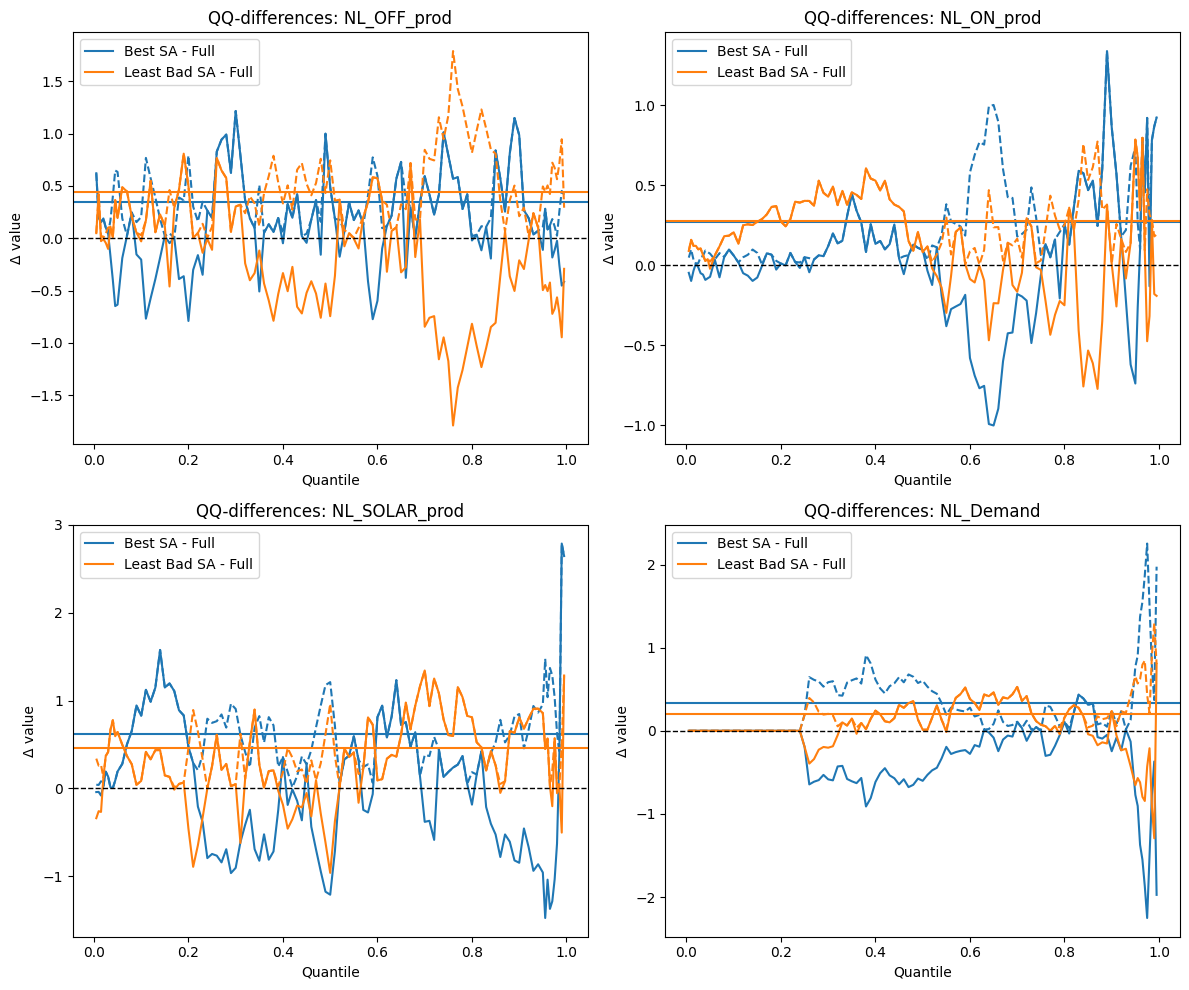

In [23]:
qq_plot(
    df_daily, {"Best SA": df_best_sa, "Least Bad SA": df_least_bad_sa}, columns=cols
)

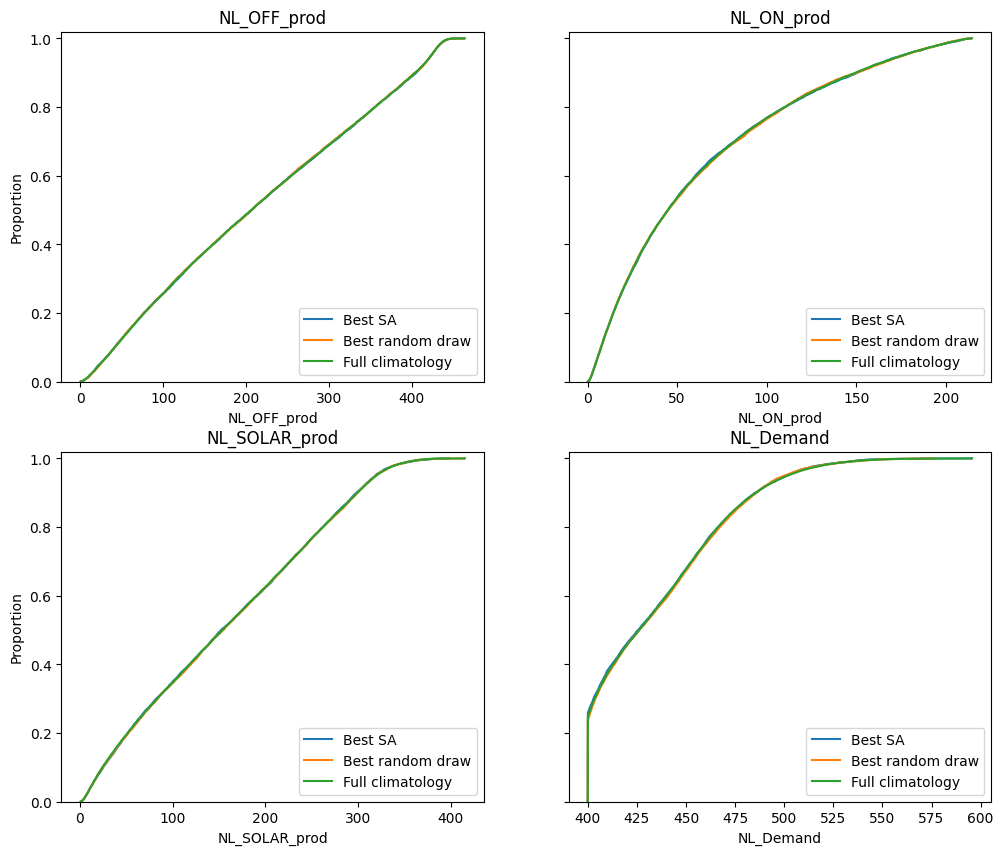

In [25]:
ecdf_comparison(
    df_daily, {"Best SA": df_best_sa, "Best random draw": df_best_random}, columns=cols
)

(<Figure size 1200x1000 with 4 Axes>, <Figure size 1200x1000 with 4 Axes>)

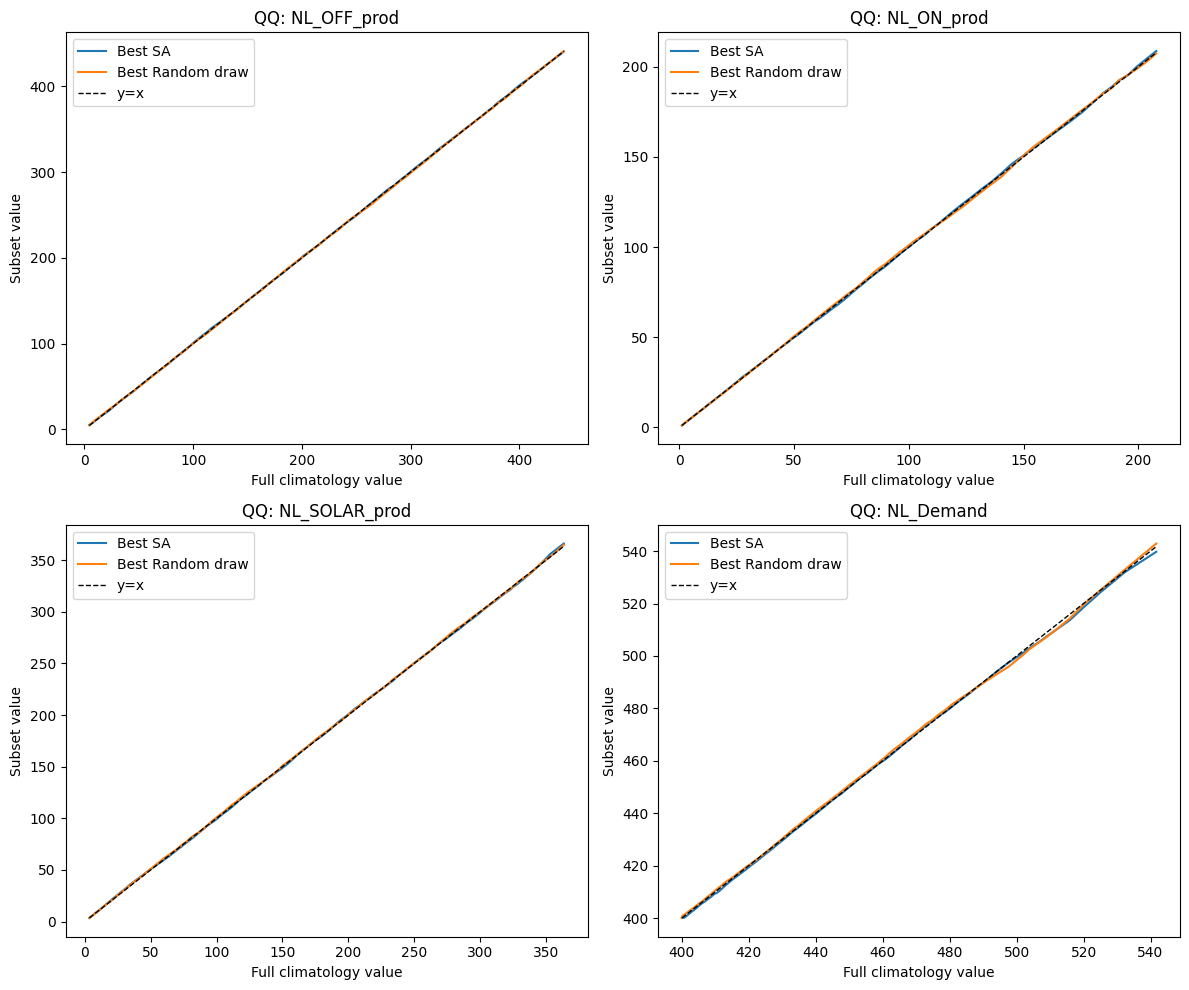

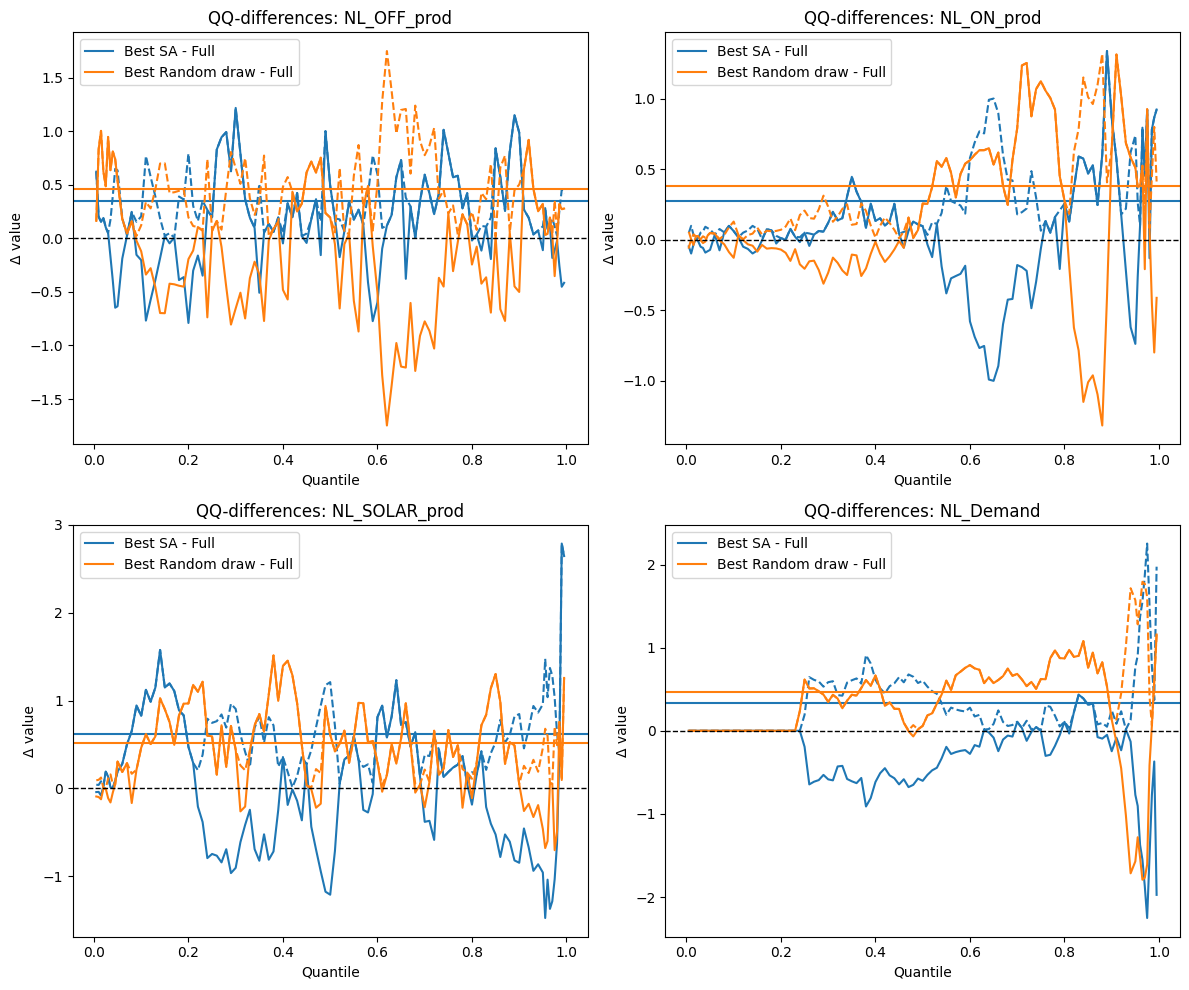

In [26]:
qq_plot(
    df_daily, {"Best SA": df_best_sa, "Best Random draw": df_best_random}, columns=cols
)

## 3.2 Best vs real random draw

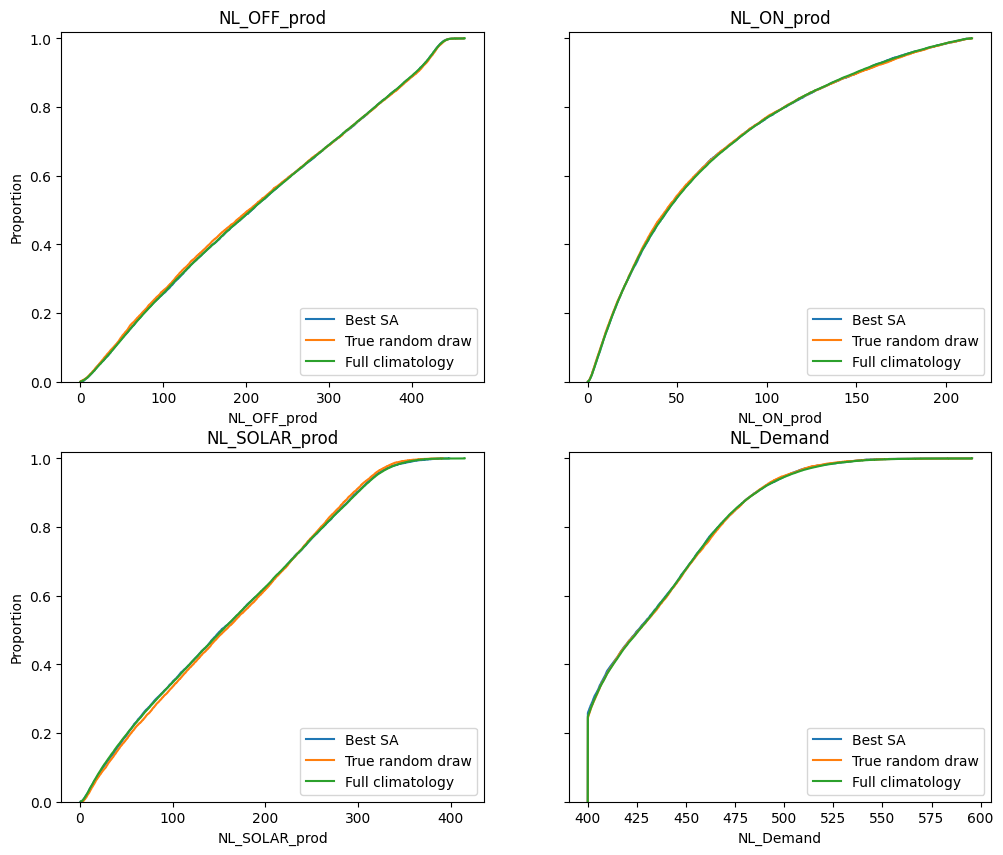

In [27]:
ecdf_comparison(
    df_daily, {"Best SA": df_best_sa, "True random draw": df_random}, columns=cols
)

(<Figure size 1200x1000 with 4 Axes>, <Figure size 1200x1000 with 4 Axes>)

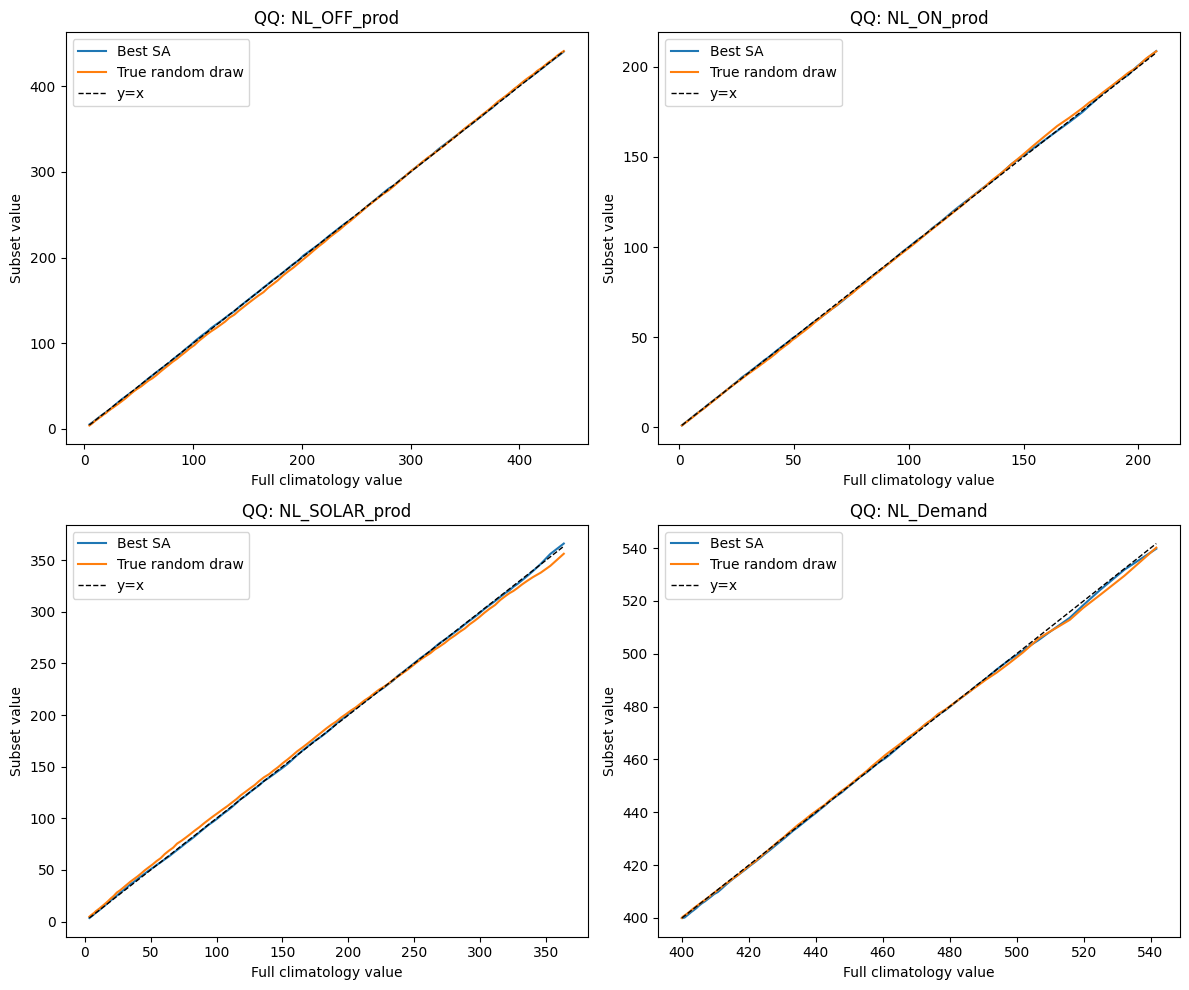

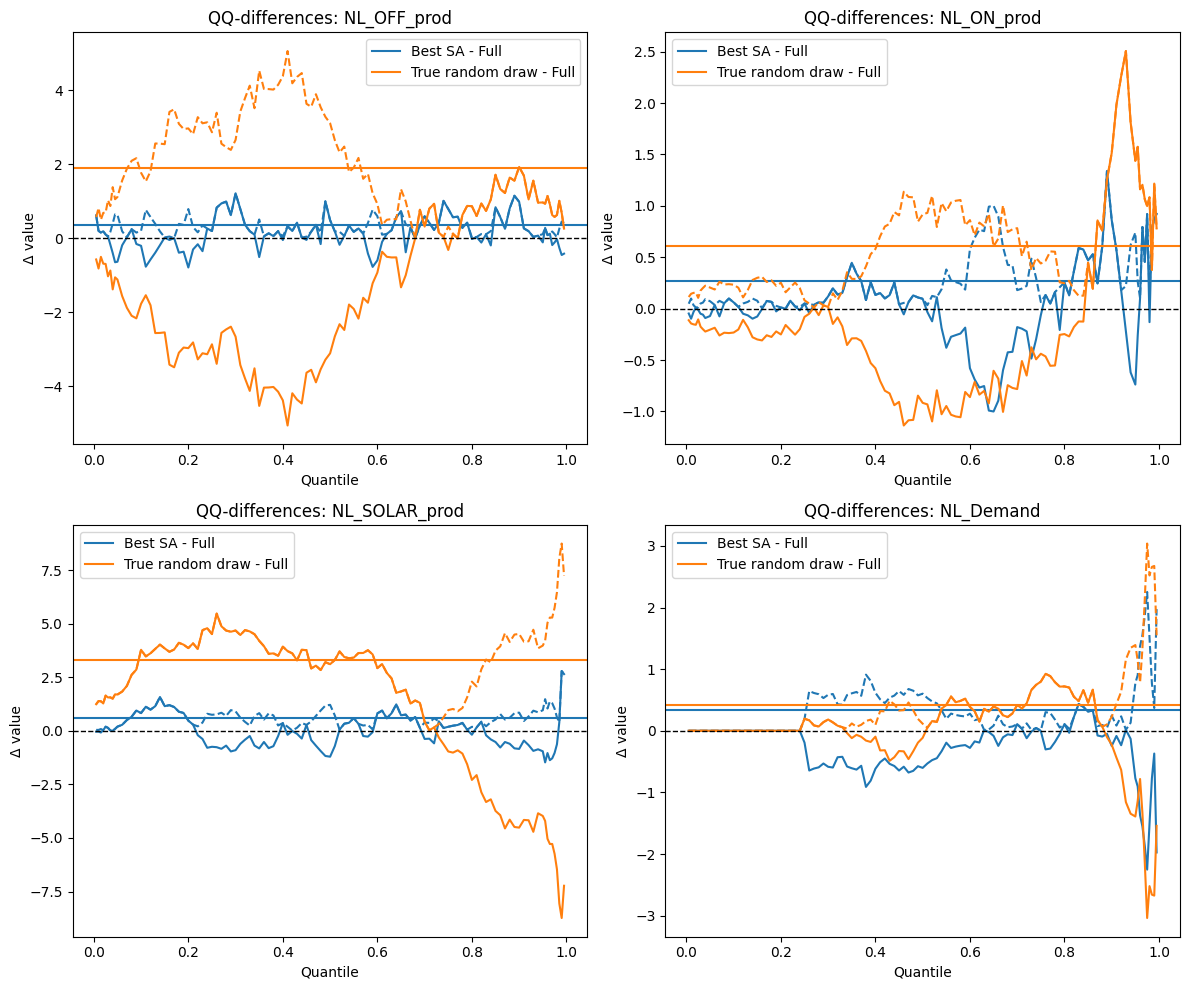

In [28]:
qq_plot(df_daily, {"Best SA": df_best_sa, "True random draw": df_random}, columns=cols)

# Seasonal matching

In [46]:
extended_summer = list(range(4, 10))
extended_winter = list(range(10, 13)) + list(range(1, 4))


df_daily_summer = df_daily.query("Date.dt.month in @extended_summer")
df_best_sa_summer = df_best_sa.query("Date.dt.month in @extended_summer")
df_least_bad_sa_summer = df_least_bad_sa.query("Date.dt.month in @extended_summer")
df_best_random_summer = df_best_random.query("Date.dt.month in @extended_summer")

(<Figure size 1200x1000 with 4 Axes>, <Figure size 1200x1000 with 4 Axes>)

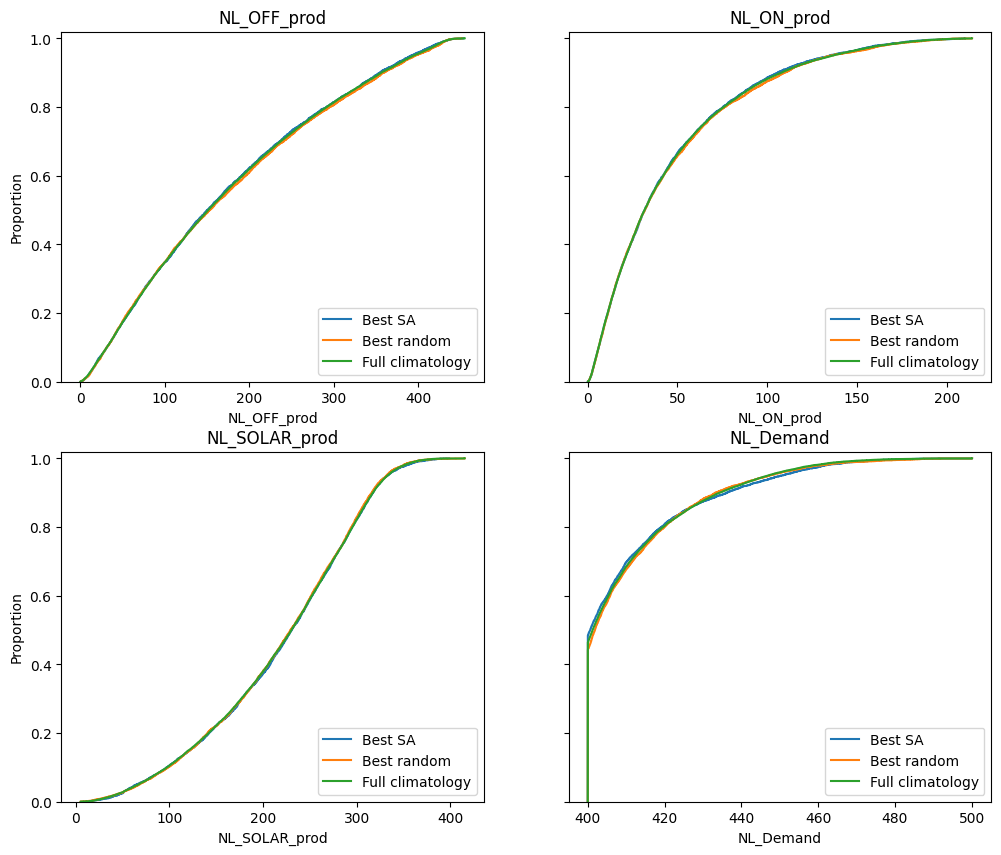

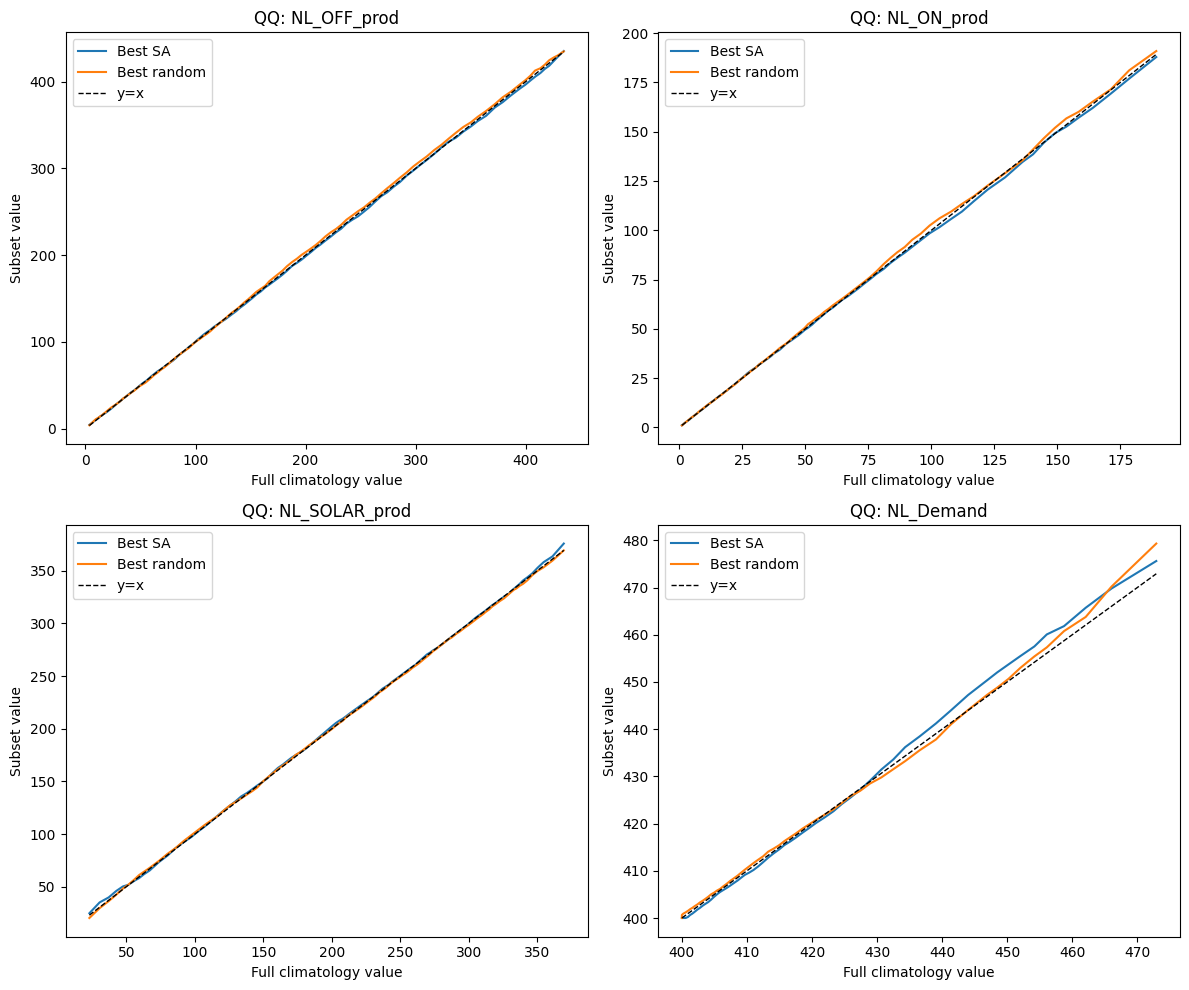

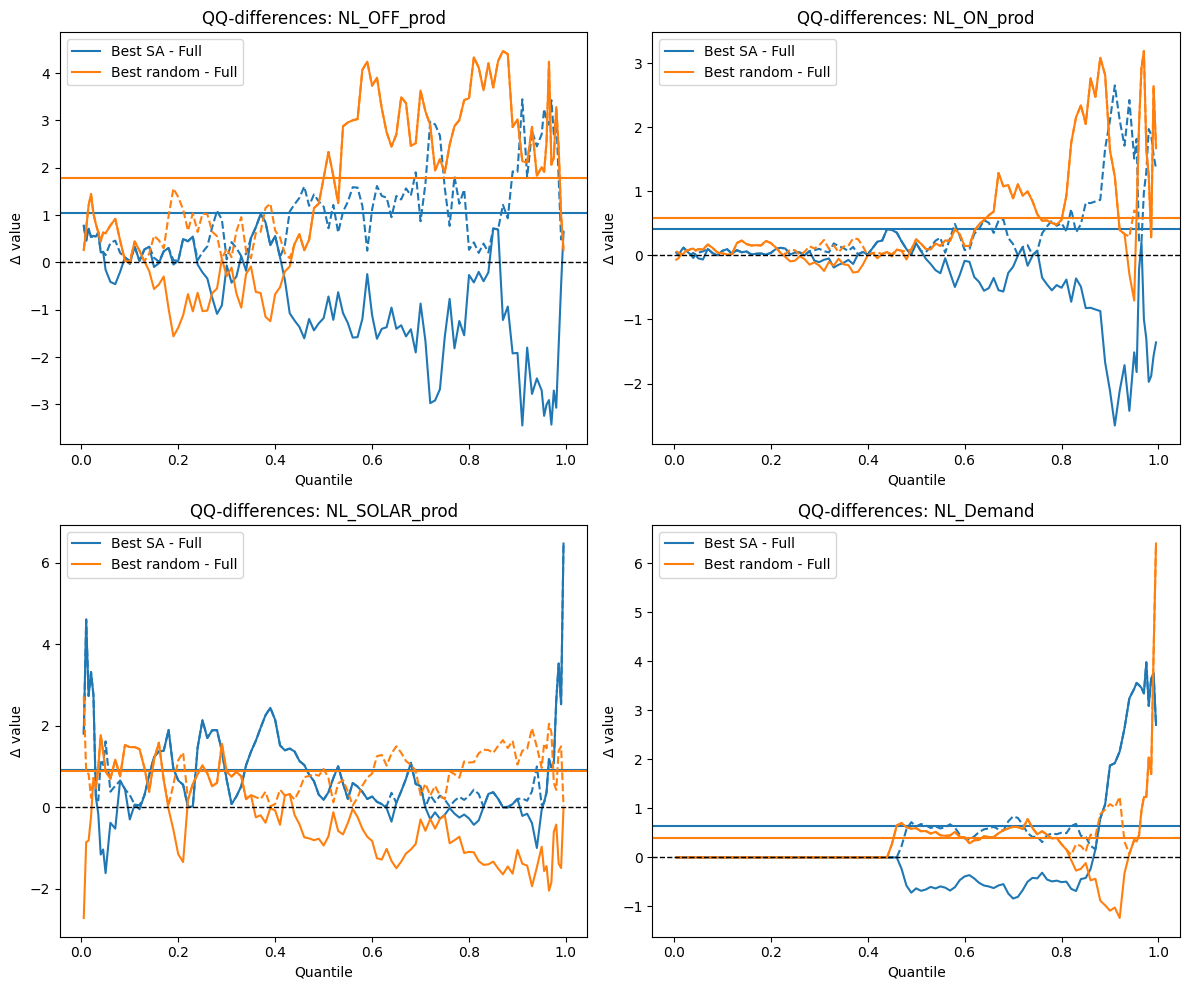

In [45]:
ecdf_comparison(
    df_daily_summer,
    {"Best SA": df_best_sa_summer, "Best random": df_best_random_summer},
    columns=cols,
)
qq_plot(
    df_daily_summer,
    {"Best SA": df_best_sa_summer, "Best random": df_best_random_summer},
    columns=cols,
)

(<Figure size 1200x1000 with 4 Axes>, <Figure size 1200x1000 with 4 Axes>)

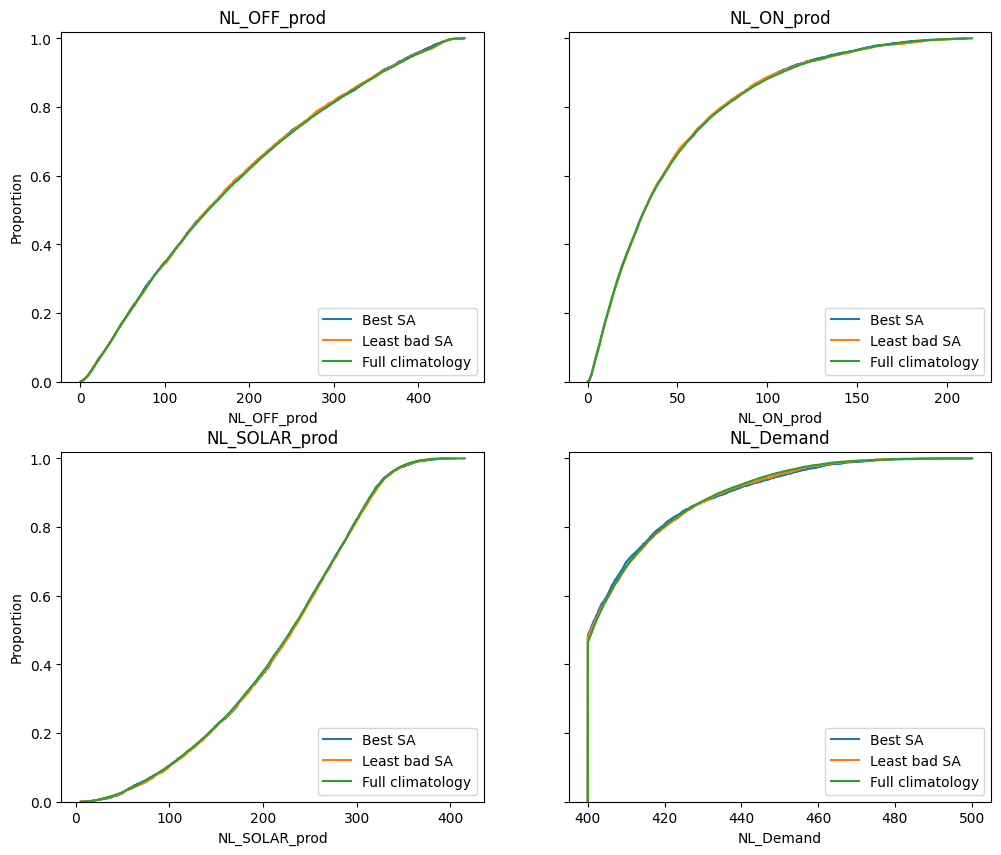

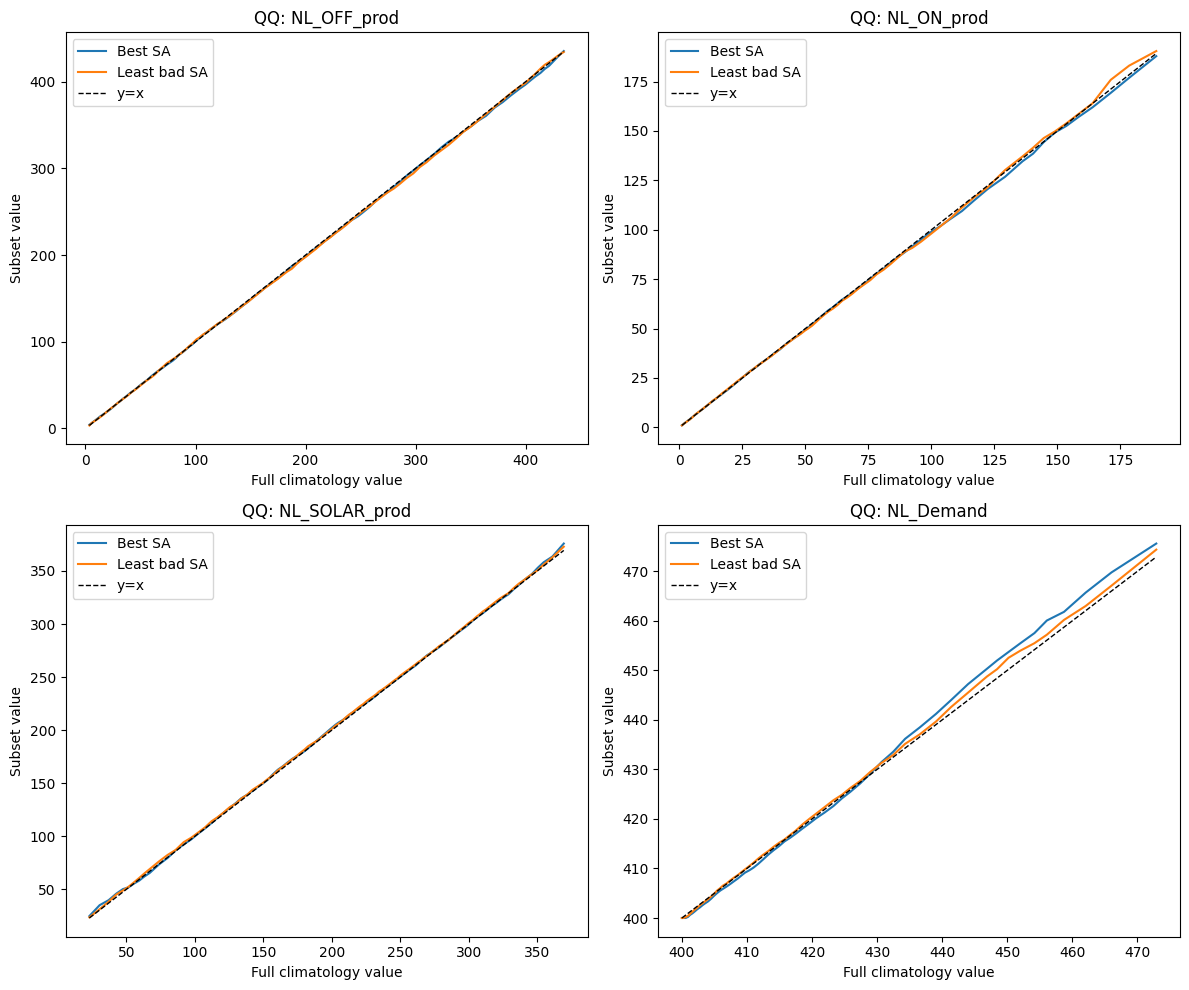

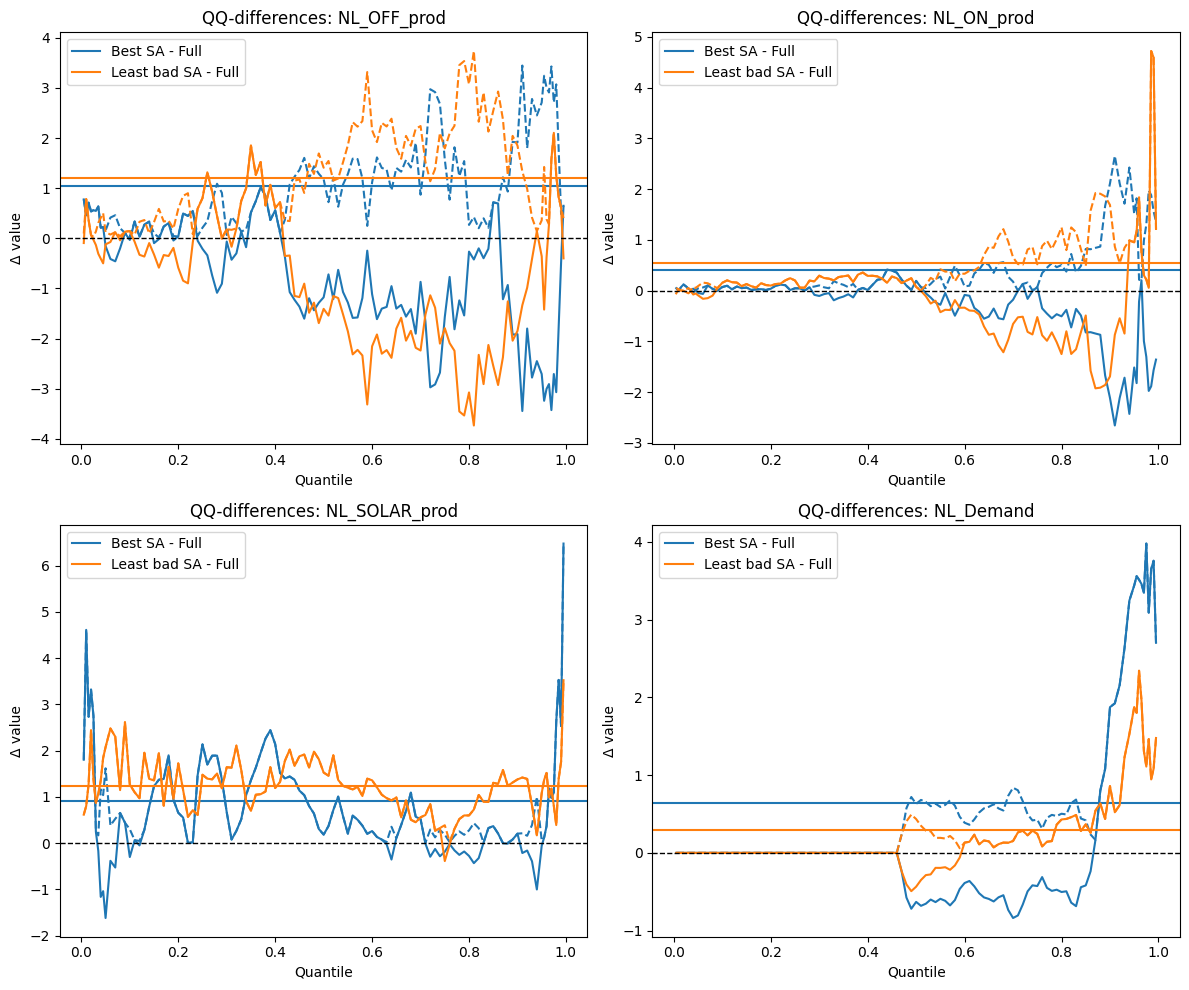

In [47]:
ecdf_comparison(
    df_daily_summer,
    {"Best SA": df_best_sa_summer, "Least bad SA": df_least_bad_sa_summer},
    columns=cols,
)
qq_plot(
    df_daily_summer,
    {"Best SA": df_best_sa_summer, "Least bad SA": df_least_bad_sa_summer},
    columns=cols,
)